In [1]:
# ---- Define Media ---- #
from media import get_medium, get_medium_dispersion

# 1) PECDV SiN Data
Si3N4 = get_medium(
    medium_key = "si3n4",
    wl_range = (1.550 - 0.200, 1.550 + 0.200),
    tolerance = 1e-5
)

# 2) Silica
SiO2 = get_medium(
    medium_key = "sio2",
    wl_range = (1.550 - 0.200, 1.550 + 0.200),
    tolerance = 5e-5
)

2026-08-28 19:46:13,285 - media.medium_helper - INFO - [Medium] Cache HIT for si3n4. Reusing Luke_Si3N4_737c6e77.json (Fit range: [1.35, 1.75], RMS: 2.66e-15, Poles allowed: 10).
2026-08-28 19:46:13,287 - media.medium_helper - INFO - [Medium] Cache HIT for sio2. Reusing Nyakuchena_fusedSilica_78358b24.json (Fit range: [1.35, 1.75], RMS: 1.32e-05, Poles allowed: 10).


### Example Ring Resonators

[Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-40.65, Z=0.175
2026-08-28 17:38:12,573 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/halfring_resonator/example_geometry.png


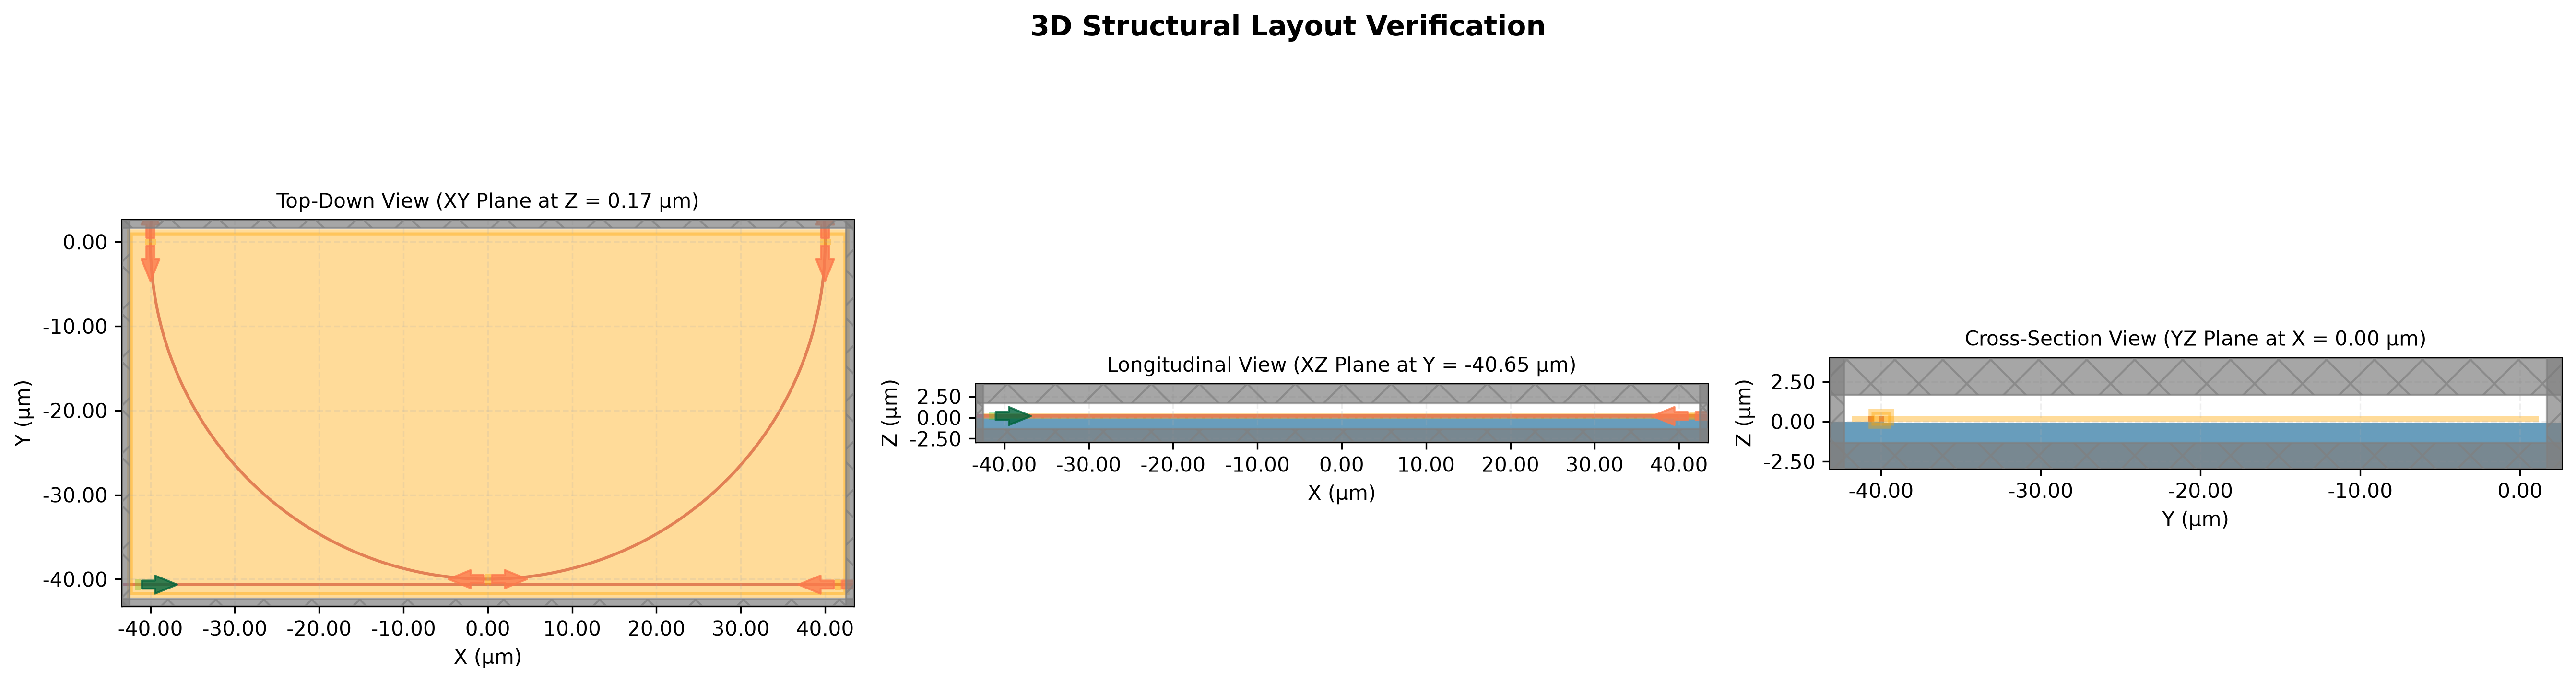

In [2]:
# Half Ring Resonator
from ringResonator import halfringResonator
from geometries import half_ring_resonator

example_halfring_resonator = half_ring_resonator.get_active_simulation(
    radius = 40.0,
    gap = 0.300,

    wg_width=0.350,
    wg_height=0.350,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    wavelength0=1.550,

    substrate_height=4.0,
)

from utilities.sim_plotter import display_3d

display_3d(
    device = example_halfring_resonator,
    output_path = "example_results/ring_resonator/halfring_resonator/example_geometry.png",
    save = True,
    coordinates = half_ring_resonator.get_optimal_plot_coords(example_halfring_resonator.sim)
)

[Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-100.85, Z=0.175
2026-08-28 17:38:32,252 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/fullring_resonator/example_geometry.png


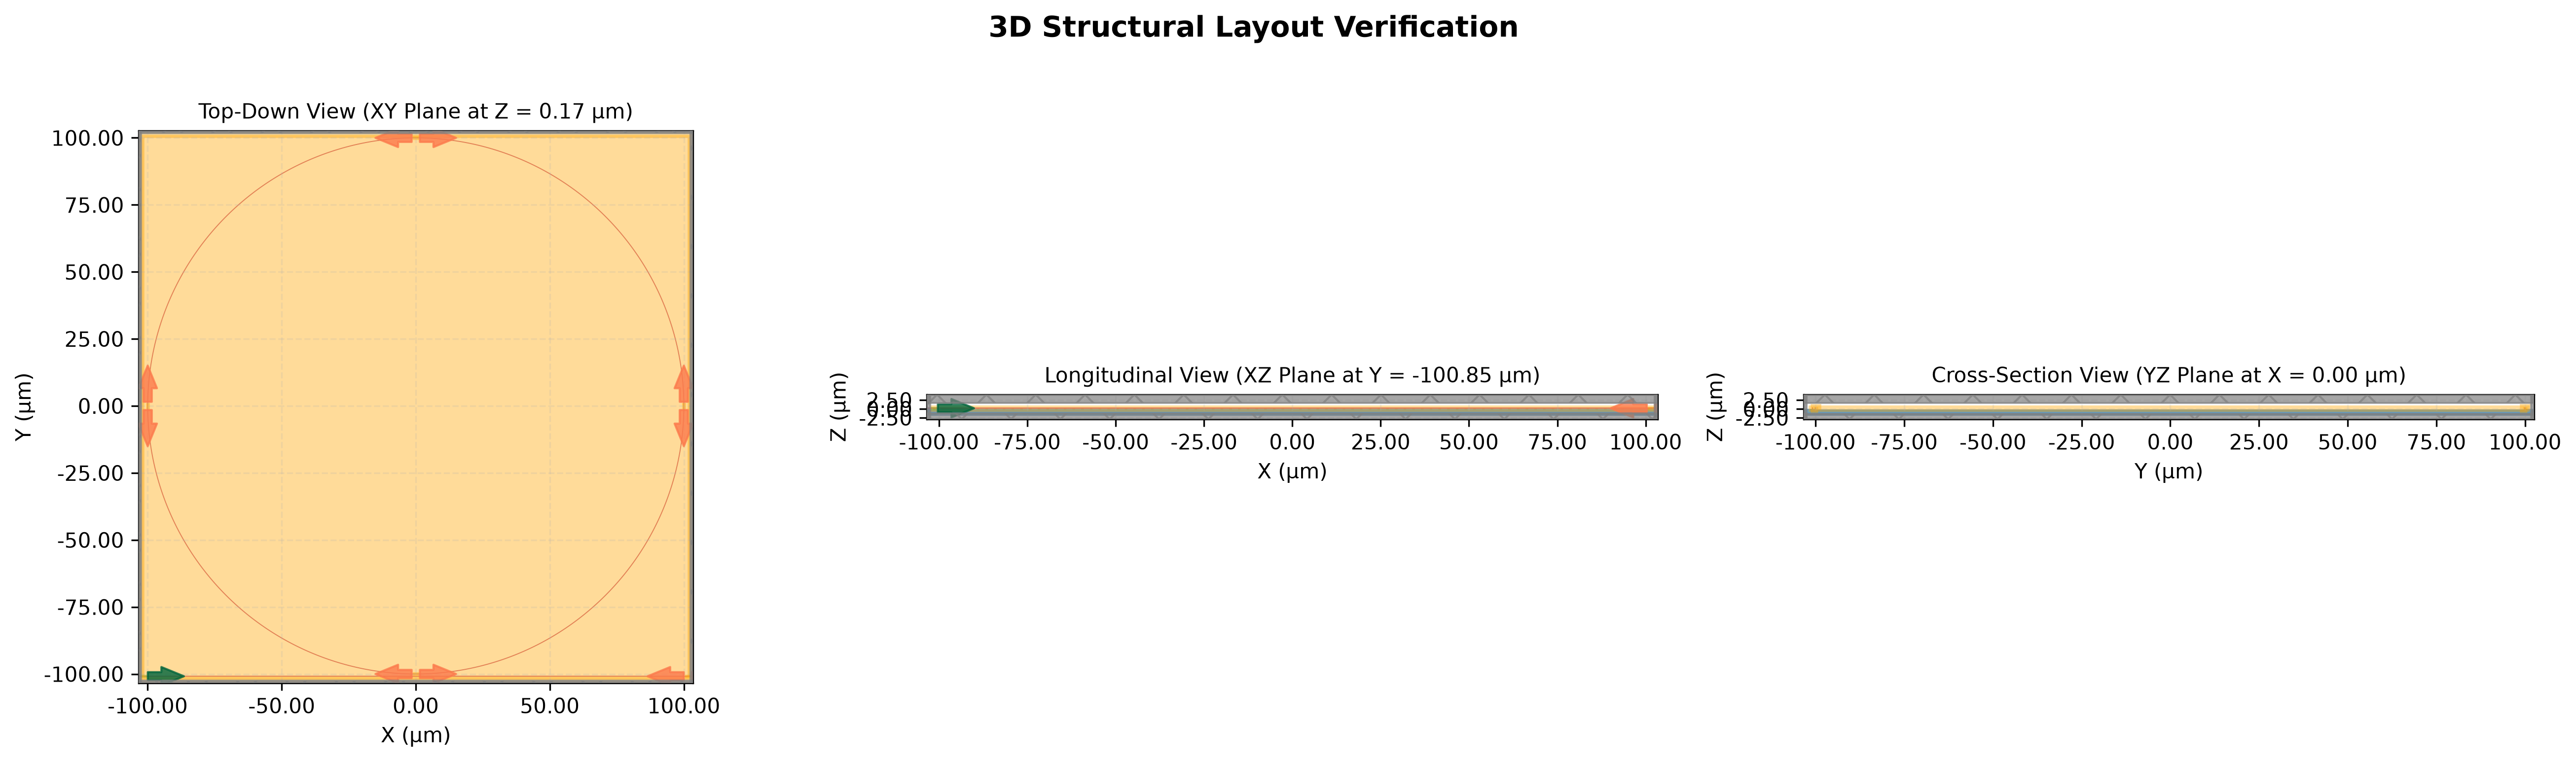

In [3]:
# Full Ring Resonator
from ringResonator import ringResonator
from geometries import full_ring_resonator

example_ring_resonator = full_ring_resonator.get_active_simulation(
    radius = 100.0,
    gap = 0.500,

    wg_width=0.350,
    wg_height=0.350,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    wavelength0=1.550,

    substrate_height=2.0,
)

from utilities.sim_plotter import display_3d

display_3d(
    device = example_ring_resonator,
    output_path = "example_results/ring_resonator/fullring_resonator/example_geometry.png",
    save = True,
    coordinates = full_ring_resonator.get_optimal_plot_coords(example_ring_resonator.sim)
)

### Partial Ring Resonators

In [2]:
# ---- Partial Ring Resonator ---- #
from geometries import partial_ring_resonator, half_ring_resonator
import numpy as np

# Define a section that considers 30 degrees of the ring
example_30_ring_resonator = partial_ring_resonator.get_passive_simulation(
    radius = 40.0,
    gap = 0.350,
    wg_width = 0.800,
    wg_height = 0.800,
    core_medium = Si3N4,
    substrate_medium = SiO2,
    wavelength0 = 1.550,
    span_angle_rad = np.radians(30)
)

from utilities.sim_plotter import display_3d

display_3d(
    device = example_30_ring_resonator,
    output_path = "example_results/ring_resonator/partial_ring_resonator/example_geometry.png",
    save = True,
    #coordinates = half_ring_resonator.get_optimal_plot_coords(example_30_ring_resonator.sim)
)

TypeError: partialRingResonator.__init__() missing 1 required positional argument: 'span_angle'

In [5]:
example_30_ring_resonator.sim.plot_3d()

### Converting Ring Types

[Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-100.85, Z=0.175
2026-08-28 17:38:55,065 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/converted2fullring_resonator/original_geometry.png


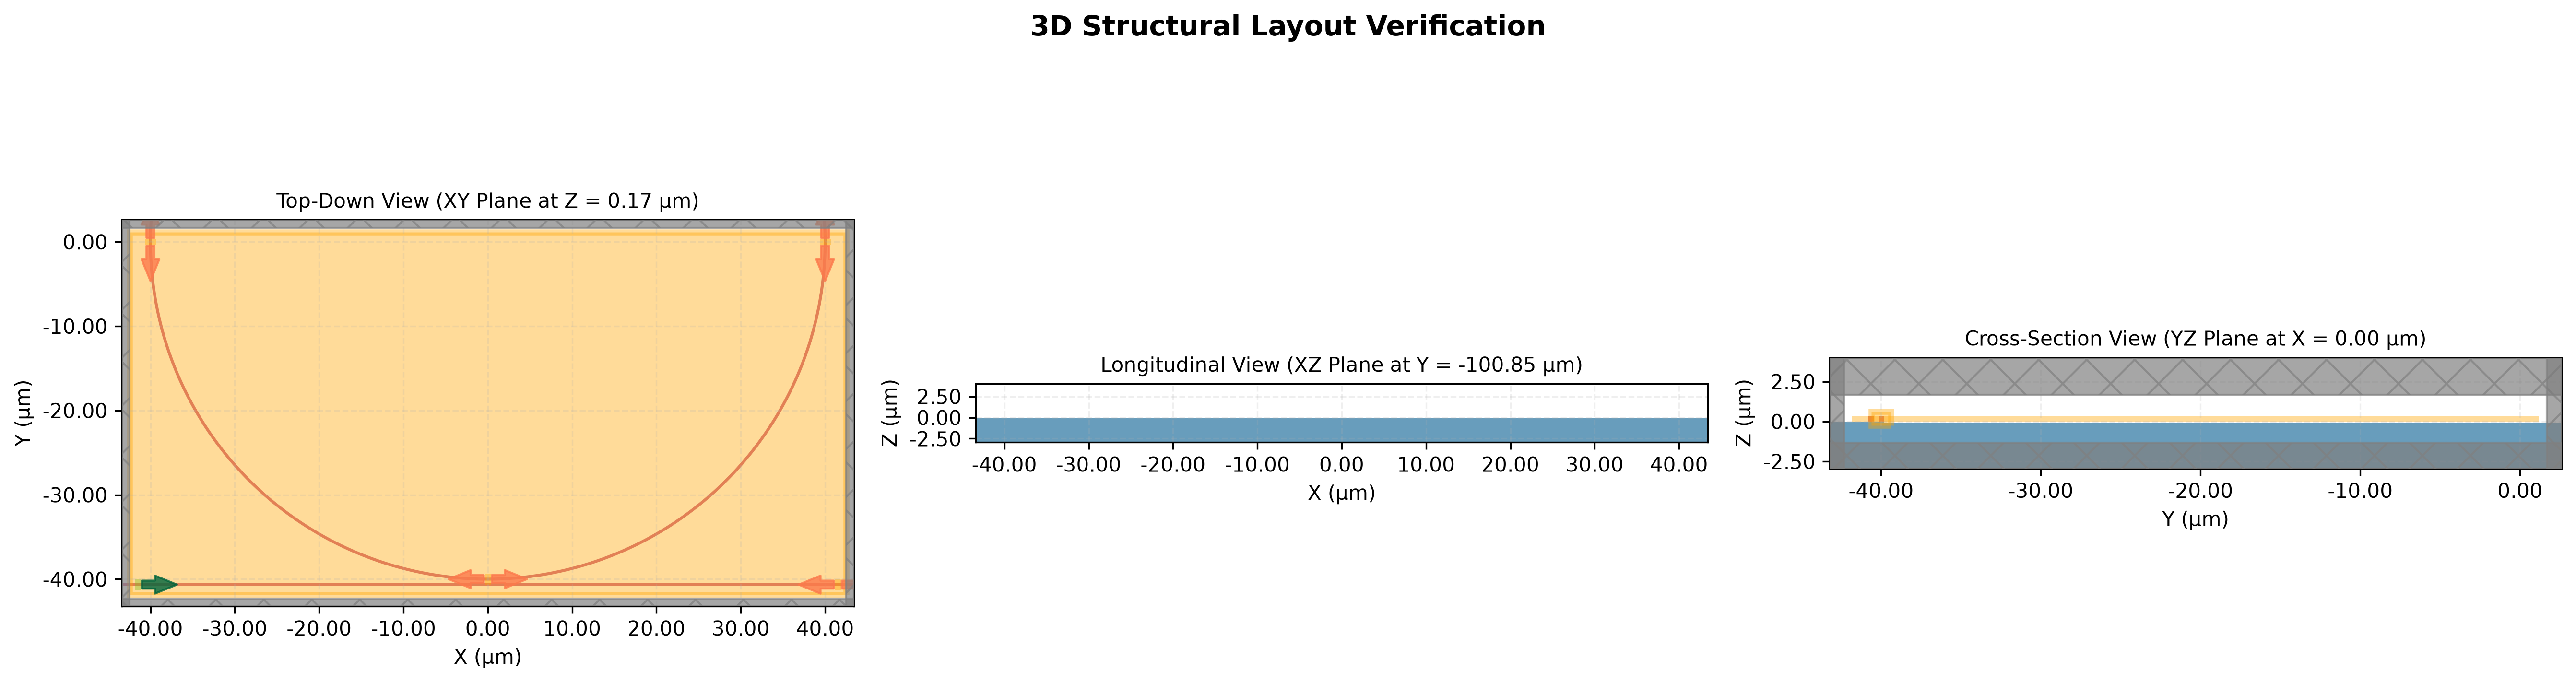

[Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-100.85, Z=0.175
2026-08-28 17:38:55,865 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/converted2fullring_resonator/converted_geometry.png


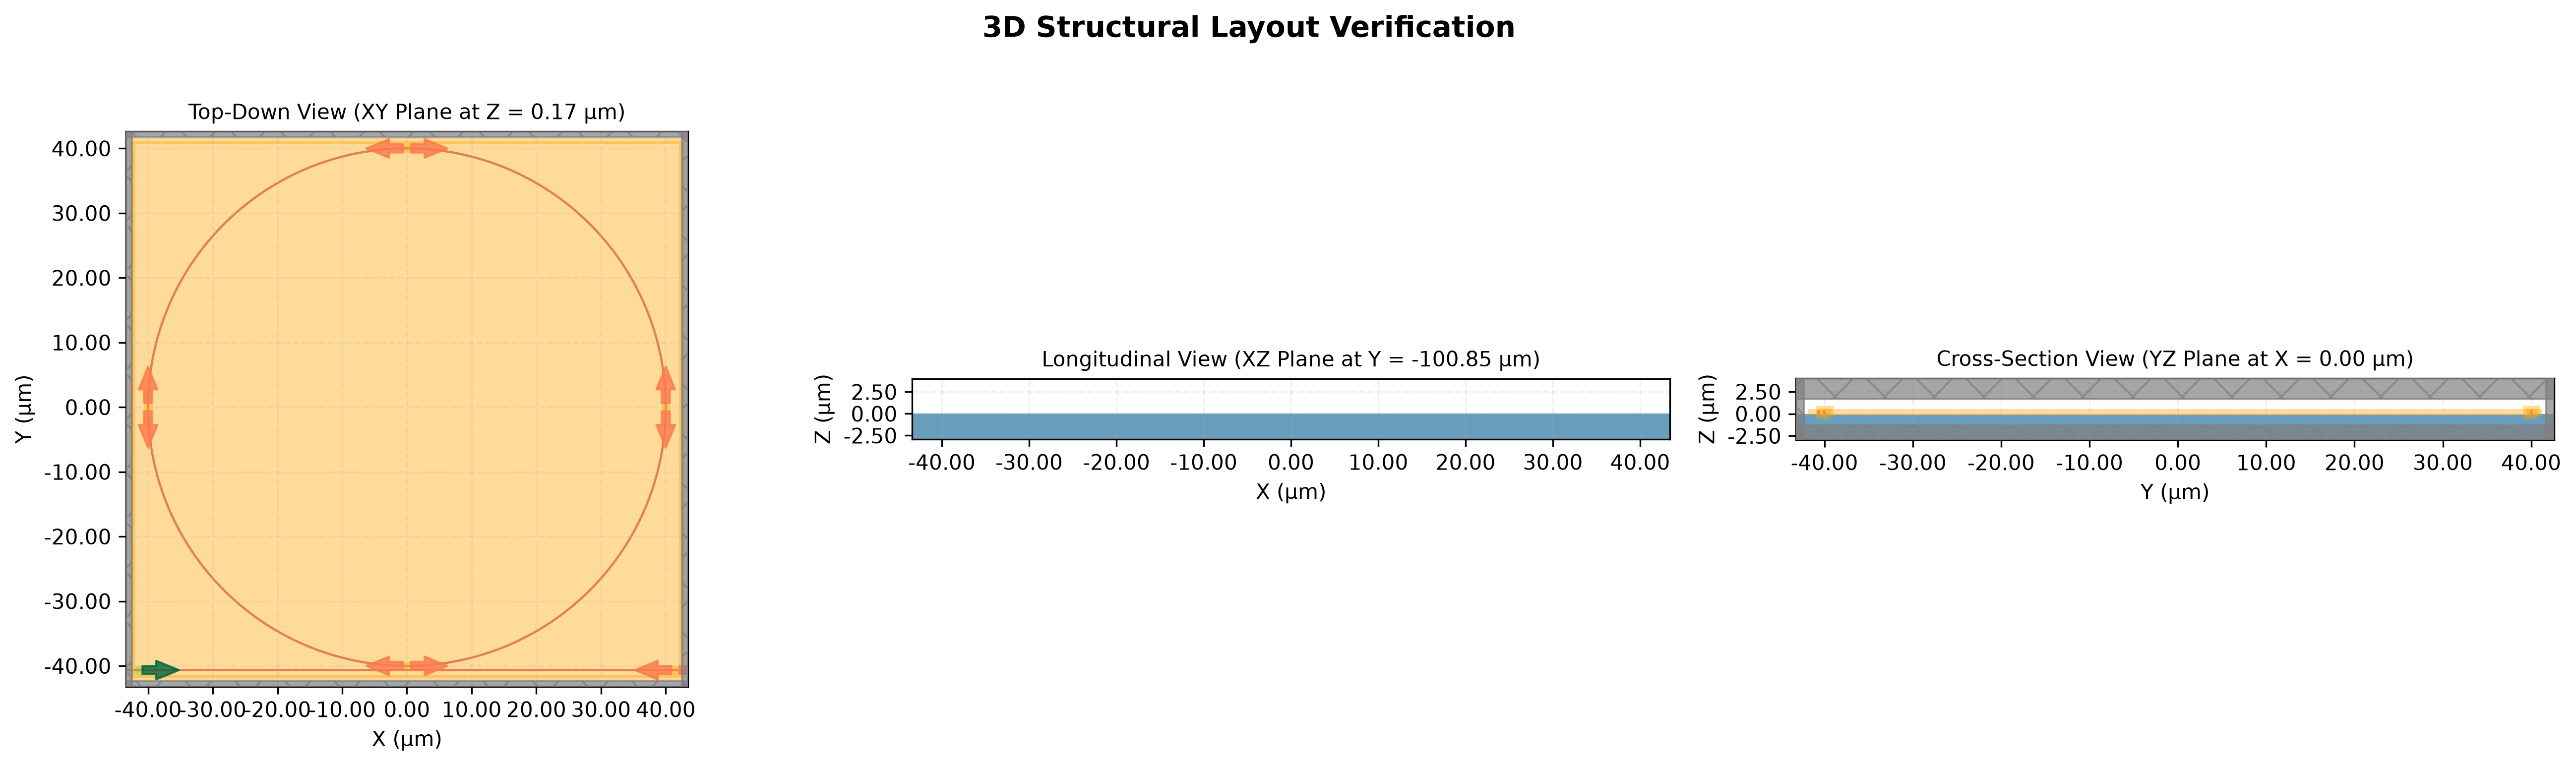

In [4]:
# ---- Converting Ring Types -- Half-ring to Full-ring ---- #

# Re-display the half-ring resonator defined two cells ago
display_3d(
    device = example_halfring_resonator,
    output_path = "example_results/ring_resonator/converted2fullring_resonator/original_geometry.png",
    save = True,
    coordinates = full_ring_resonator.get_optimal_plot_coords(example_ring_resonator.sim)
)

# Convert to full-ring geometry.
converted_ring_resonator = example_halfring_resonator.to_full_ring(active = True)

display_3d(
    device = converted_ring_resonator,
    output_path = "example_results/ring_resonator/converted2fullring_resonator/converted_geometry.png",
    save = True,
    coordinates = full_ring_resonator.get_optimal_plot_coords(example_ring_resonator.sim)
)

[Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-100.85, Z=0.175
2026-08-28 17:39:00,088 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/converted2halfring_resonator/original_geometry.png


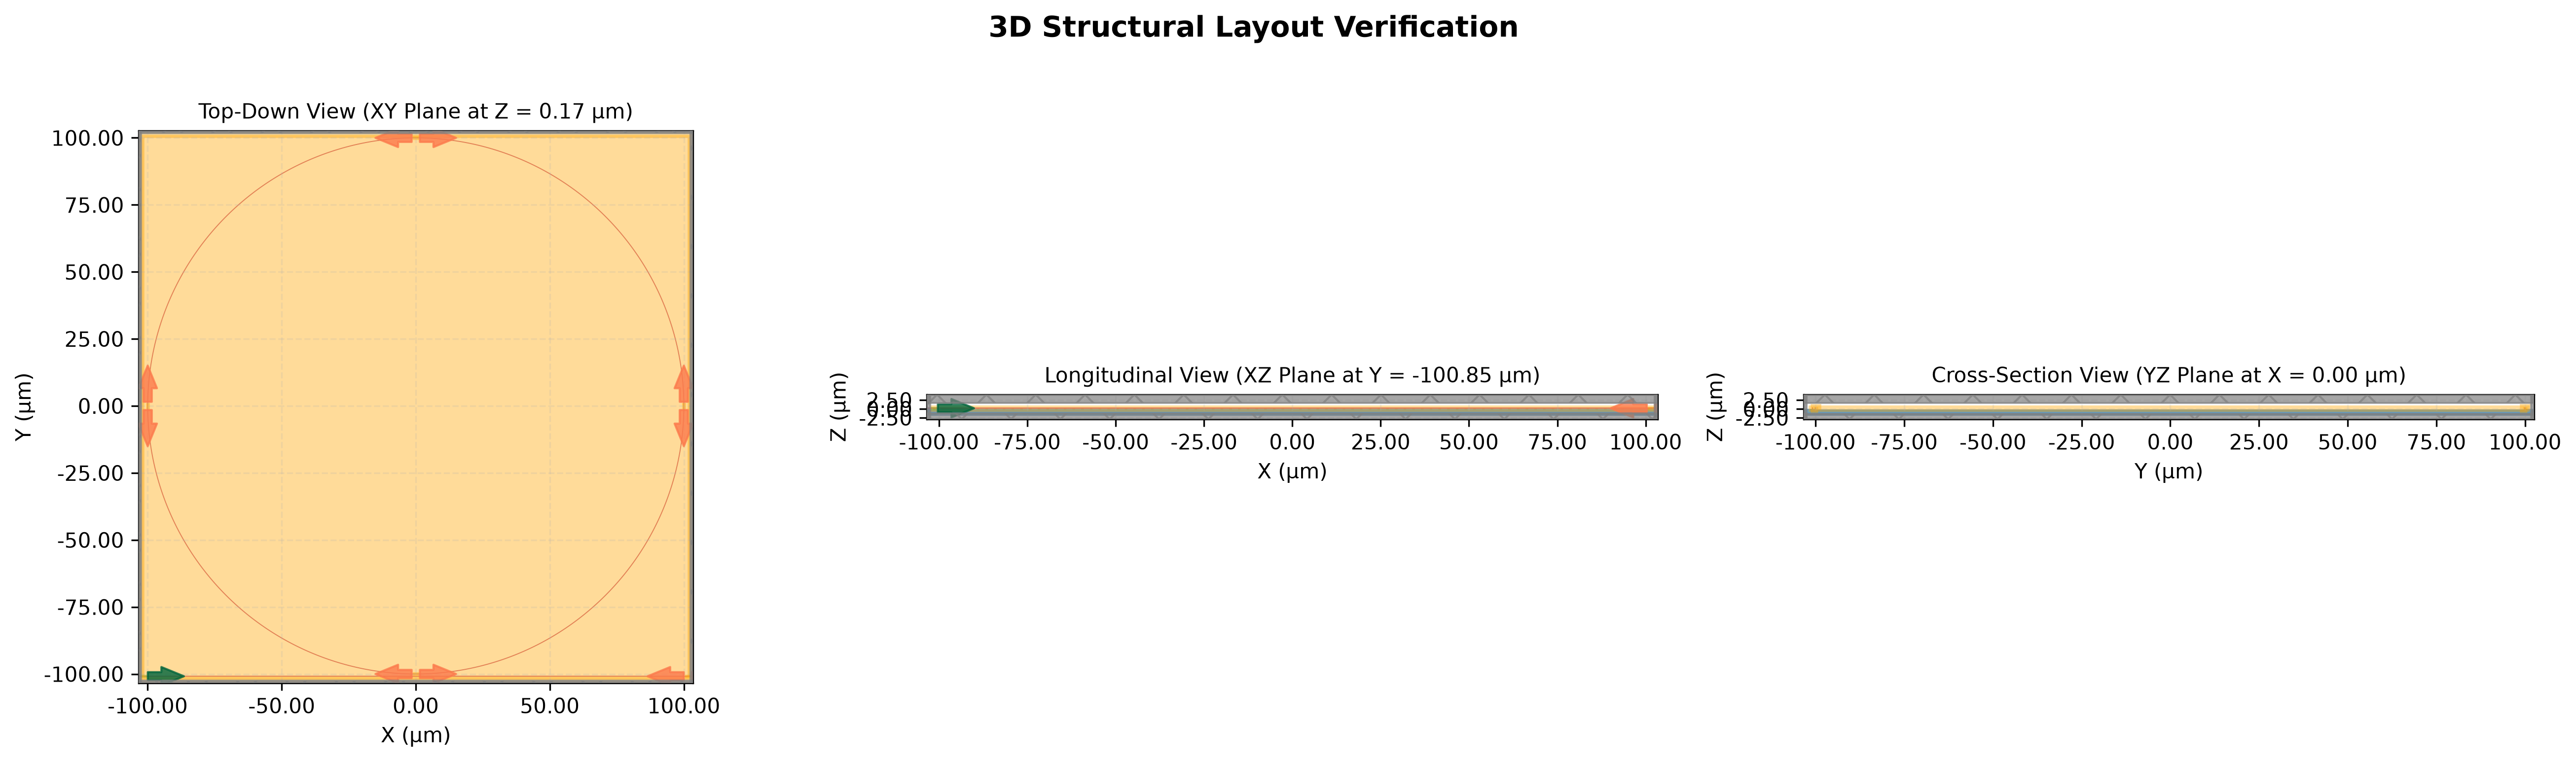

[Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-100.85, Z=0.175
2026-08-28 17:39:00,823 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/converted2halfring_resonator/converted_geometry.png


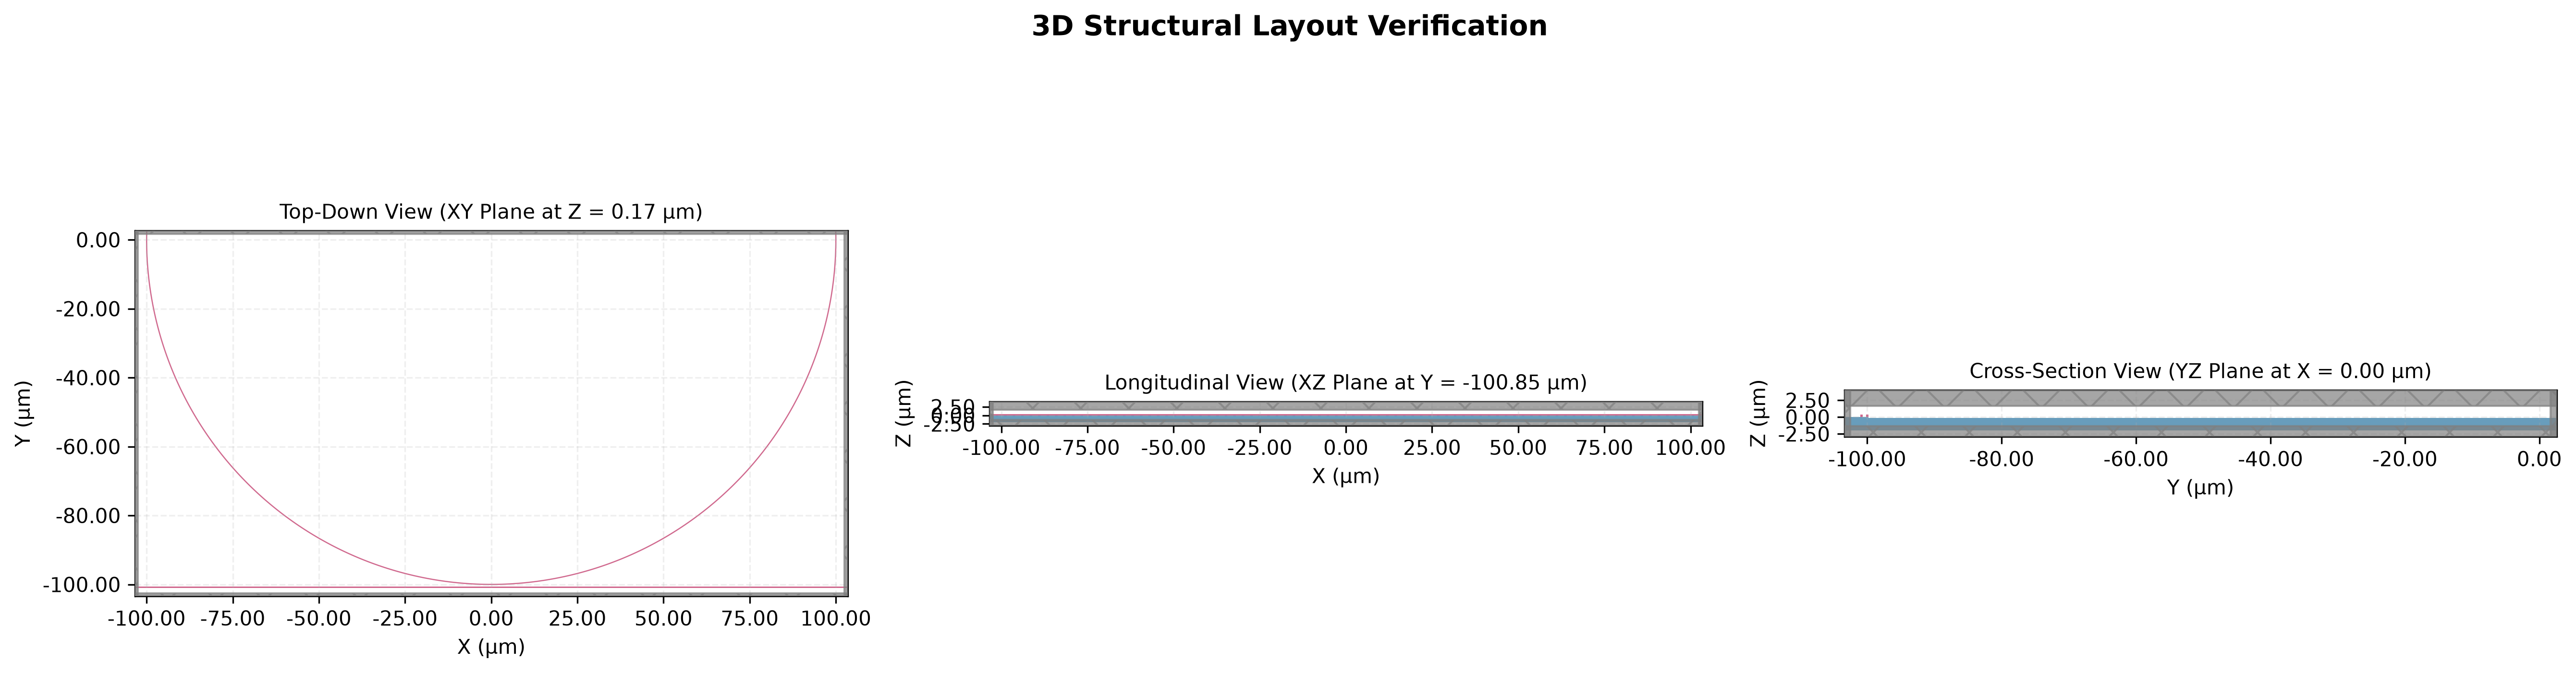

In [5]:
# ---- Converting Ring Types -- Full-ring to Half-ring ---- #

# Re-display the half-ring resonator defined two cells ago
display_3d(
    device = example_ring_resonator,
    output_path = "example_results/ring_resonator/converted2halfring_resonator/original_geometry.png",
    save = True,
    coordinates = full_ring_resonator.get_optimal_plot_coords(example_ring_resonator.sim)
)

# Convert to full-ring passive geometry
converted_halfring_resonator = example_ring_resonator.to_half_ring(
    active = False # Generate a passive simulation, if you'd like to
)

display_3d(
    device = converted_halfring_resonator,
    output_path = "example_results/ring_resonator/converted2halfring_resonator/converted_geometry.png",
    save = True,
    coordinates = full_ring_resonator.get_optimal_plot_coords(example_ring_resonator.sim)
)

### Ring Resonator Standalone Arcs

In [ ]:
# ---- Generate Ring Resonator Arcs ---- #
from ringResonator import resonator_arc
from geometries import resonator_arc
from utilities.sim_plotter import display_2d, display_3d

# -- Example 90 Degrees -- #
example_90_arc = resonator_arc.get_active_simulation(
    wavelength0 = 1.550,

    radius = 40.0,

    wg_width = 0.800,
    wg_height = 0.800,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    bend_angle_deg = 90
)

display_3d(
    device = example_90_arc,
    output_path = "example_results/ring_resonator/resonator_arcs/example_90deg_arc.png",
    save = True,
    coordinates = resonator_arc.get_optimal_plot_coords(example_90_arc.sim)
)

# -- Example 180 Degrees -- #
example_180_arc = resonator_arc.get_active_simulation(
    wavelength0 = 1.550,

    radius = 40.0,

    wg_width = 0.800,
    wg_height = 0.800,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    bend_angle_deg = 180
)

display_3d(
    device = example_180_arc,
    output_path = "example_results/ring_resonator/resonator_arcs/example_180deg_arc.png",
    save = True,
    coordinates = resonator_arc.get_optimal_plot_coords(example_180_arc.sim)
)

In [ ]:
# -- Example theta Degrees Arc -- #
from ringResonator import resonator_arc
from geometries import resonator_arc
from utilities.sim_plotter import display_2d, display_3d

# TODO
theta = 270 # Degrees

example_theta_arc = resonator_arc.get_active_simulation(
    wavelength0 = 1.550,

    radius = 40.0,

    wg_width = 0.800,
    wg_height = 0.800,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    bend_angle_deg = theta
)

display_3d(
    device = example_theta_arc,
    output_path = "example_results/ring_resonator/resonator_arcs/example_270deg_arc.png",
    save = True,
    coordinates = resonator_arc.get_optimal_plot_coords(example_theta_arc.sim)
)

### Partial Rings + Waveguide

In [ ]:
# ---- Define Media ---- #
from media import get_medium, get_medium_dispersion

# 1) PECDV SiN Data
Si3N4 = get_medium(
    medium_key = "si3n4",
    wl_range = (1.550 - 0.200, 1.550 + 0.200),
    tolerance = 1e-5
)

# 2) Silica
SiO2 = get_medium(
    medium_key = "sio2",
    wl_range = (1.550 - 0.200, 1.550 + 0.200),
    tolerance = 5e-5
)

In [ ]:
from ringResonator import partialRingResonator
from geometries import partial_ring_resonator

example_partialring_resonator = partial_ring_resonator.get_active_simulation(
    radius=40.0,
    gap=0.300,
    wg_width=0.350,
    wg_height=0.350,
    core_medium=Si3N4,
    substrate_medium=SiO2,
    wavelength0=1.550,
    span_angle=30.0,
    substrate_height=4.0,
)

from utilities.sim_plotter import display_3d

display_3d(
    device=example_partialring_resonator,
    output_path="example_results/ring_resonator/partialring_resonator/example_geometry_10deg.png",
    save=True,
    coordinates=partial_ring_resonator.get_optimal_plot_coords(
        example_partialring_resonator.sim
    ),
)

In [ ]:
# The Ablation Study
from pathlib import Path
import numpy as np
from ringResonator import halfringResonator, partialRingResonator
from geometries import half_ring_resonator, partial_ring_resonator

# Output Directory for Ablation Study
ablation_dir = Path("example_results/ablation_study/30deg_vs_halfring")
ablation_dir.mkdir(parents=True, exist_ok=True)

# Common Physics & Geometry Parameters
base_params = dict(
    radius=40.0,
    gap=0.300,
    wg_width=0.800,
    wg_height=0.800,
    core_medium=Si3N4,
    substrate_medium=SiO2,
    wavelength0=1.550,
    substrate_height=4.0,
)

# 1. Instantiate Active Simulations
half_ring_dev = half_ring_resonator.get_active_simulation(**base_params)
partial_ring_dev = partial_ring_resonator.get_active_simulation(
    span_angle=30.0, **base_params
)

# 2. Execute Cloud Simulations
sim_data_half = half_ring_dev.run_sim(
    output_dir=ablation_dir, task_name="ablation_half_ring"
)
sim_data_partial = partial_ring_dev.run_sim(
    output_dir=ablation_dir, task_name="ablation_partial_ring_30deg"
)

# 3. Plot & Save Field Intensity Maps
half_ring_dev.plot_field(
    sim_data_half,
    monitor_name="coupling_field_map",
    output_path=ablation_dir / "half_ring_field.png",
    save=True,
    show=False,
)

partial_ring_dev.plot_field(
    sim_data_partial,
    monitor_name="coupling_field_map",
    output_path=ablation_dir / "partial_ring_30deg_field.png",
    save=True,
    show=False,
)


# 4. Compute Coupling Metrics
def extract_coupling_efficiency(sim_data) -> tuple[float, float]:
    """Calculates through-port power transmission (T) and cross-coupling efficiency (κ²)."""
    amp_thru = sim_data["Through_Out"].amps.sel(direction="+", mode_index=0).item()
    t_thru = float(np.abs(amp_thru) ** 2)
    coupling_eff = (1.0 - t_thru) * 100.0
    return t_thru, coupling_eff


t_half, eta_half = extract_coupling_efficiency(sim_data_half)
t_partial, eta_partial = extract_coupling_efficiency(sim_data_partial)

# 5. Summary Log
print("\n" + "=" * 55)
print("  ABLATION STUDY: Half-Ring vs 30° Partial-Ring")
print("=" * 55)
print(f"Half-Ring Resonator:")
print(f"  • Through Transmission (T): {t_half:.4f} ({t_half * 100:.2f}%)")
print(f"  • Cross-Coupling (κ²):     {eta_half:.2f}%\n")
print(f"30° Partial-Ring Resonator:")
print(f"  • Through Transmission (T): {t_partial:.4f} ({t_partial * 100:.2f}%)")
print(f"  • Cross-Coupling (κ²):     {eta_partial:.2f}%\n")
print(f"Absolute Coupling Delta:     {abs(eta_half - eta_partial):.2f}%")
print("=" * 55)

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from ringResonator import halfringResonator, partialRingResonator
from geometries import half_ring_resonator, partial_ring_resonator

# Output Directory for Extended Radius Ablation
ablation_dir = Path("example_results/ablation_study/radius_sweep_30deg_vs_halfring")
ablation_dir.mkdir(parents=True, exist_ok=True)

# Radius Sweep Configuration (µm)
RADII_SWEEP = [10.0, 20.0, 40.0, 80.0, 110.0]
SPAN_ANGLE = 30.0

# Base Physics & Geometry Parameters
base_params = dict(
    gap=0.300,
    wg_width=0.800,
    wg_height=0.800,
    core_medium=Si3N4,
    substrate_medium=SiO2,
    wavelength0=1.550,
    substrate_height=4.0,
)


def extract_coupling_efficiency(sim_data) -> tuple[float, float]:
    """Calculates through-port power transmission (T) and cross-coupling efficiency (κ²)."""
    amp_thru = sim_data["Through_Out"].amps.sel(direction="+", mode_index=0).item()
    t_thru = float(np.abs(amp_thru) ** 2)
    coupling_eff = (1.0 - t_thru) * 100.0
    return t_thru, coupling_eff


results = []

# Loop over radii
for r in RADII_SWEEP:
    print(f"\n[Ablation] Processing Radius R = {r:.1f} µm...")
    r_dir = ablation_dir / f"R_{r:.0f}um"
    r_dir.mkdir(parents=True, exist_ok=True)

    current_params = {**base_params, "radius": r}

    # 1. Instantiate Active Simulations
    half_ring_dev = half_ring_resonator.get_active_simulation(**current_params)
    partial_ring_dev = partial_ring_resonator.get_active_simulation(
        span_angle=SPAN_ANGLE, **current_params
    )

    # 2. Run Simulations
    sim_data_half = half_ring_dev.run_sim(
        output_dir=r_dir, task_name=f"ablation_half_ring_R{r:.0f}"
    )
    sim_data_partial = partial_ring_dev.run_sim(
        output_dir=r_dir, task_name=f"ablation_partial_ring_30deg_R{r:.0f}"
    )

    # 3. Plot Fields
    half_ring_dev.plot_field(
        sim_data_half,
        monitor_name="coupling_field_map",
        output_path=r_dir / "half_ring_field.png",
        save=True,
        show=False,
    )
    partial_ring_dev.plot_field(
        sim_data_partial,
        monitor_name="coupling_field_map",
        output_path=r_dir / "partial_ring_30deg_field.png",
        save=True,
        show=False,
    )

    # 4. Extract Metrics
    t_half, eta_half = extract_coupling_efficiency(sim_data_half)
    t_partial, eta_partial = extract_coupling_efficiency(sim_data_partial)
    delta_eta = abs(eta_half - eta_partial)

    results.append({
        "radius": r,
        "t_half": t_half,
        "eta_half": eta_half,
        "t_partial": t_partial,
        "eta_partial": eta_partial,
        "delta": delta_eta,
    })

# 5. Generate Radius vs. Delta Plot
radii = [res["radius"] for res in results]
eta_half_list = [res["eta_half"] for res in results]
eta_part_list = [res["eta_partial"] for res in results]
deltas = [res["delta"] for res in results]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

# Plot 1: Absolute Coupling Comparison
ax1.plot(
    radii,
    eta_half_list,
    "o-",
    color="tab:blue",
    linewidth=2,
    label="Half-Ring (180°)",
)
ax1.plot(
    radii,
    eta_part_list,
    "s--",
    color="tab:orange",
    linewidth=2,
    label="Partial-Ring (30°)",
)
ax1.set_xlabel("Radius $R$ ($\mu m$)", fontsize=11)
ax1.set_ylabel("Cross-Coupling Efficiency $\kappa^2$ (%)", fontsize=11)
ax1.set_title("Coupling Efficiency vs. Radius", fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.legend()

# Plot 2: Absolute Delta Scaling
ax2.plot(radii, deltas, "d-", color="tab:red", linewidth=2.5, markersize=8)
ax2.set_xlabel("Radius $R$ ($\mu m$)", fontsize=11)
ax2.set_ylabel("Absolute Discrepancy $|\Delta \kappa^2|$ (%)", fontsize=11)
ax2.set_title("Architecture Discrepancy vs. Radius", fontsize=12)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(ablation_dir / "radius_sweep_delta_trend.png", dpi=300)
plt.close()

# 6. Console Summary Table
print("\n" + "=" * 70)
print("  RADIUS SWEEP ABLATION: Half-Ring vs 30° Partial-Ring")
print("=" * 70)
print(
    f"{'Radius (µm)':<12} | {'Half-Ring κ² (%)':<18} | {'30° Partial κ² (%)':<20} | {'Delta (%)':<10}"
)
print("-" * 70)
for res in results:
    print(
        f"{res['radius']:<12.1f} | {res['eta_half']:<18.2f} | {res['eta_partial']:<20.2f} | {res['delta']:<10.2f}"
    )
print("=" * 70)

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import tidy3d as td

ablation_dir = Path("example_results/ablation_study/radius_sweep_30deg_vs_halfring")
RADII_SWEEP = [10.0, 20.0, 40.0, 80.0, 110.0]


def extract_coupling_efficiency(sim_data: td.SimulationData) -> tuple[float, float]:
    """Extracts through-port power transmission (T) and cross-coupling efficiency (κ²)."""
    amp_thru = (
        sim_data["Through_Out"].amps.sel(direction="+", mode_index=0).item()
    )
    t_thru = float(np.abs(amp_thru) ** 2)
    coupling_eff = (1.0 - t_thru) * 100.0
    return t_thru, coupling_eff


# Reload cached simulation data from disk
results = []
for r in RADII_SWEEP:
    r_dir = ablation_dir / f"R_{r:.0f}um"
    file_half = r_dir / f"ablation_half_ring_R{r:.0f}.hdf5"
    file_partial = r_dir / f"ablation_partial_ring_30deg_R{r:.0f}.hdf5"

    sim_data_half = td.SimulationData.from_file(str(file_half))
    sim_data_partial = td.SimulationData.from_file(str(file_partial))

    _, eta_half = extract_coupling_efficiency(sim_data_half)
    _, eta_partial = extract_coupling_efficiency(sim_data_partial)
    delta_eta = abs(eta_half - eta_partial)

    results.append({
        "radius": r,
        "eta_half": eta_half,
        "eta_partial": eta_partial,
        "delta": delta_eta,
    })

radii = [res["radius"] for res in results]
eta_half_list = [res["eta_half"] for res in results]
eta_part_list = [res["eta_partial"] for res in results]
deltas = [res["delta"] for res in results]

# Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

# 1. Absolute Coupling Efficiency Comparison
ax1.plot(
    radii,
    eta_half_list,
    "o-",
    color="tab:blue",
    linewidth=2,
    markersize=7,
    label="Half-Ring (180°)",
)
ax1.plot(
    radii,
    eta_part_list,
    "s--",
    color="tab:orange",
    linewidth=2,
    markersize=7,
    label="Partial-Ring (30°)",
)
ax1.set_xlabel("Radius $R$ ($\mu m$)", fontsize=11)
ax1.set_ylabel("Cross-Coupling Efficiency $\kappa^2$ (%)", fontsize=11)
ax1.set_title("Coupling Efficiency vs. Radius", fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.legend(frameon=True)

# 2. Architecture Discrepancy Scaling
ax2.plot(
    radii,
    deltas,
    "d-",
    color="tab:red",
    linewidth=2.5,
    markersize=8,
    label="$|\Delta \kappa^2|$",
)
ax2.set_xlabel("Radius $R$ ($\mu m$)", fontsize=11)
ax2.set_ylabel("Absolute Discrepancy $|\Delta \kappa^2|$ (%)", fontsize=11)
ax2.set_title("Architecture Discrepancy vs. Radius", fontsize=12)
ax2.grid(True, alpha=0.3)
ax2.legend(frameon=True)

plt.tight_layout()
plt.savefig(
    ablation_dir / "radius_sweep_delta_trend_replot.png", bbox_inches="tight"
)
plt.show()

In [ ]:
from tidy3d import web
web.configure("IsYK44DHZ8v3NtXzwdi3xqHxcOKeyti2CZ3L18IwRwR8tTbm")

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import tidy3d as td

ablation_dir = Path("example_results/ablation_study/radius_sweep_30deg_vs_halfring_abs")
RADII_SWEEP = [10.0, 20.0, 40.0, 80.0, 110.0]


def extract_coupling_efficiency(sim_data: td.SimulationData) -> tuple[float, float]:
    """Extracts through-port power transmission (T) and cross-coupling efficiency (κ²)."""
    amp_thru = (
        sim_data["Through_Out"].amps.sel(direction="+", mode_index=0).item()
    )
    t_thru = float(np.abs(amp_thru) ** 2)
    coupling_eff = (1.0 - t_thru) * 100.0
    return t_thru, coupling_eff


# Reload cached simulation data from disk
results = []
for r in RADII_SWEEP:
    r_dir = ablation_dir / f"R_{r:.0f}um"
    file_half = r_dir / f"ablation_half_ring_R{r:.0f}.hdf5"
    file_partial = r_dir / f"ablation_partial_ring_30deg_R{r:.0f}.hdf5"

    sim_data_half = td.SimulationData.from_file(str(file_half))
    sim_data_partial = td.SimulationData.from_file(str(file_partial))

    _, eta_half = extract_coupling_efficiency(sim_data_half)
    _, eta_partial = extract_coupling_efficiency(sim_data_partial)
    delta_eta = abs(eta_half - eta_partial)

    results.append({
        "radius": r,
        "eta_half": eta_half,
        "eta_partial": eta_partial,
        "delta": delta_eta,
    })

radii = [res["radius"] for res in results]
eta_half_list = [res["eta_half"] for res in results]
eta_part_list = [res["eta_partial"] for res in results]
deltas = [res["delta"] for res in results]

# Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

# 1. Absolute Coupling Efficiency Comparison
ax1.plot(
    radii,
    eta_half_list,
    "o-",
    color="tab:blue",
    linewidth=2,
    markersize=7,
    label="Half-Ring (180°)",
)
ax1.plot(
    radii,
    eta_part_list,
    "s--",
    color="tab:orange",
    linewidth=2,
    markersize=7,
    label="Partial-Ring (30°)",
)
ax1.set_xlabel("Radius $R$ ($\mu m$)", fontsize=11)
ax1.set_ylabel("Cross-Coupling Efficiency $\kappa^2$ (%)", fontsize=11)
ax1.set_title("Coupling Efficiency vs. Radius", fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.legend(frameon=True)

# 2. Architecture Discrepancy Scaling
ax2.plot(
    radii,
    deltas,
    "d-",
    color="tab:red",
    linewidth=2.5,
    markersize=8,
    label="$|\Delta \kappa^2|$",
)
ax2.set_xlabel("Radius $R$ ($\mu m$)", fontsize=11)
ax2.set_ylabel("Absolute Discrepancy $|\Delta \kappa^2|$ (%)", fontsize=11)
ax2.set_title("Architecture Discrepancy vs. Radius", fontsize=12)
ax2.grid(True, alpha=0.3)
ax2.legend(frameon=True)

plt.tight_layout()
plt.savefig(
    ablation_dir / "radius_sweep_delta_trend_replot.png", bbox_inches="tight"
)
plt.show()